In [1]:
import os
import emcee
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

import belfast.mcmc_utils as mcmc
from belfast.target_utils import query_data
from belfast.target_definition import Target
from belfast.paths import REPO_ROOT, RESULTS_DIR, DATA_DIR

%load_ext autoreload
%autoreload 2

# Prepare data


### You may run a test using mock data generated from PARSEC V2.0 isochrones

In [ ]:
target_name =      'late SGB star' # df index 799786
cluster =          ''
true_values = np.array([2.150183, 907.005666, -0.023, 0.6, 0.524, 10])
obs_mags = np.array([0.890000, 1.243000, 0.366000, 1.919, 1.156, -0.196, -0.513, -0.572])+5
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        23
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.2
extinction =       0.01
extinction_err =   0.01
extinction_type =  'A_V'

In [ ]:
target_name =      'early SGB star' # df index 728899
cluster =          ''
true_values = np.array([2.149134, 902.007191, -0.023, 0.6, 0.524, 10])
obs_mags = np.array([0.452,0.544,0.282,0.702,0.532,0.097,0.048,0.021])+5
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        52
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.2
extinction =       0.01
extinction_err =   0.01
extinction_type =  'A_V'

In [ ]:
target_name =      'MS-SGB boundary star' # df index 728899
cluster =          ''
true_values = np.array([2.150431, 899.994800, -0.023, 0.6, 0.524, 10])
obs_mags = np.array([0.369, 0.417, 0.277, 0.499, 0.424, 0.163, 0.154, 0.131])+5
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        57
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.2
extinction =       0.01
extinction_err =   0.01
extinction_type =  'A_V'

In [ ]:
target_name =      'ending MS star' # df index 629581
cluster =          ''
true_values = np.array([2.150507, 894.993745, -0.023, 0.6, 0.524, 10])
obs_mags = np.array([0.586, 0.710, 0.361, 0.923, 0.687, 0.129, 0.049, 0.020])+5
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        48
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.2
extinction =       0.01
extinction_err =   0.01
extinction_type =  'A_V'

In [ ]:
target_name =      'late MS star' # df index 289881
cluster =          ''
true_values = np.array([2.15086, 871.00370, -0.023, 0.6, 0.524, 10])
obs_mags = np.array([0.674, 0.813, 0.423, 1.052, 0.786, 0.170, 0.076, 0.045])+5
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        46
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.2
extinction =       0.01
extinction_err =   0.01
extinction_type =  'A_V'

In [2]:

target_name =      'almost risky MS star' # df index 6208024
cluster =          ''
true_values = np.array([2., 870, -0.023, 0.8, 0.524, 10])
obs_mags = np.array([1.06043454, 1.14616631, 0.90001102, 1.29864125, 1.1372367 , 0.72862669, 0.68494916, 0.65995451])+5
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        82
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.2
extinction =       0.01
extinction_err =   0.01
extinction_type =  'A_V'

In [ ]:
target_name =      'safe MS star' # df index 6208024
cluster =          ''
true_values = np.array([2.15024, 615.99899, 0, 0.6, 0.524, 10])
obs_mags = np.array([0.948, 0.980, 0.887, 1.042, 0.994, 0.809, 0.818, 0.797])+5
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        62
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.2
extinction =       0.01
extinction_err =   0.01
extinction_type =  'A_V'

# Set Target

In [3]:
target = Target(name = target_name,
                bands_list = ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks'],
                obs_mags = obs_mags,
                obs_err_mags = obs_err_mags,
                vsini_obs = vsini_obs,
                vsini_obs_err = vsini_obs_err,
                parallax_obs = parallax_obs,
                parallax_obs_err = parallax_obs_err,
                sigma_adjustment_parameter = 1,
                extinction_parameter = True,
                true_values=False,
                )

In [4]:
# sample all parameters
target.add_info(cluster=cluster,
                sampling_variables_list = ['Mini', 'Age', 'MH', 'omega_ini', 'Inclination', 'parallax'],
                extinction=extinction,
                extinction_err=extinction_err,
                extinction_type=extinction_type
)

target.known_parameter(true_values=true_values) # for mock stars, you may set the true values and overplot them on corner plots

In [ ]:
# # if you want to sample with fixed metallicity [M/H] = 0.0, please give the value by target.known_parameter()
# target.add_info(cluster=cluster,
#                 sampling_variables_list = ['Mini', 'Age', 'omega_ini', 'Inclination', 'parallax'], # not sampling MH
#                 extinction=extinction,
#                 extinction_err=extinction_err,
#                 extinction_type=extinction_type
# )
#
# target.known_parameter(known_MH=0) # giving fixed MH here

In [ ]:
# # If assuming non-rotation
# target.add_info(cluster=cluster,
#                 sampling_variables_list = ['Mini', 'Age', 'MH', 'parallax'], # not sampling omega_ini and inclination
#                 extinction=extinction,
#                 extinction_err=extinction_err,
#                 extinction_type=extinction_type
# )
#
# target.known_parameter(known_omega_ini=1e-8, known_Inclination=1e-8)

# Set method

In [ ]:
# # Standard Regularization + METHOD DIRECT
#
# target.set_method(
#     grids_type='Mini',
#     label_list=[0, 1],
#     METHOD='DIRECT',
# )

In [ ]:
# # # Standard Regularization + METHOD PARS
#
# target.set_method(
#     grids_type='Mini',
#     label_list=[0, 1],
#     METHOD='PARS',
# )

In [5]:
# Reparameterized Regularization + METHOD DIRECT

target.set_method(
    grids_type='u',
    label_list=[0, 1],
    METHOD='DIRECT',
)

****************************************************************************************************
Using PARSEC isochrones with u grids and DIRECT method.
****************************************************************************************************
Loaded u-regularized grid.
grid_type: with_inc
label_list: [0, 1]
interp_variable_list: ['Mini', 'Age', 'MH', 'omega_ini', 'Inclination']
interp_variable_list_regular: ['u', 'Age', 'MH', 'omega_ini', 'Inclination']
interp_output_list: ['Mass', 'omega', 'logL', 'logTe', 'Req', 'Rpol', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
u_grid shape: (1392,)
grid_outputs shape: (1392, 219, 13, 7, 11, 14)
grid_bounds shape: (219, 13, 7, 11, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
read_all_at_once: True
save_float32: True
u_save_range: [0.0, 1.0]
u_grid_was_cropped: False
n_u_original: 1392
n_u_saved: 1392
total grid memory: 16298.61 MB (15.92 GB)


In [ ]:
# # Reparameterized Regularization + METHOD PARS
#
# target.set_method(
#     grids_type='u',
#     label_list=[0, 1],
#     METHOD='PARS',
# )

In [ ]:
# # MIST isochrones + METHOD PARS
#
# target.set_method(
#     grids_type='Mini',
#     iso_name='MIST',
#     METHOD='PARS',
# )

# Sampling

In [6]:
target.interp_lower_limit[1] = 100

In [7]:
# Set initial states and prior distributions for sampling.

target.set_sampling(n_walkers=30,
                    MH_prior = lambda x: norm.logpdf(x, loc=true_values[2], scale=0.05*2),
                    # inclination_prior = lambda x: norm.logpdf(x, loc=np.deg2rad(30), scale=np.deg2rad(6)),
                    extinction_prior = lambda x: norm.logpdf(x, loc=extinction, scale=extinction_err),
                    )

Sampling parameter space:
Parameter           Min        Max
----------------------------------
Mini             0.0900    13.9997
Age            100.0000  2001.0134
MH              -2.1917     0.3363
omega_ini        0.0000     0.9900
Inclination      0.0000     1.5708
parallax         5.0000    15.0000
sigma            0.0000     0.1000
extinction       0.0000     1.0000


Estimating rough mass...


100%|██████████| 3000/3000 [00:16<00:00, 180.62it/s]


Rough mass is 2.03 M_sun.
====> Using default Vrot prior: 1.80-2.20 Msun
Running a test with 3000 samples...


100%|██████████| 3000/3000 [00:16<00:00, 177.37it/s]


acceptance ratio:
	0.17 0.18 0.18 0.15 0.18 0.19 0.17 0.16 0.14 
	0.20 0.17 0.16 0.16 0.19 0.15 0.21 0.18 0.17 
	0.19 0.17 0.20 0.18 0.16 0.20 0.17 0.15 0.15 
	0.20 0.20 0.18 
mean acceptance ratio: 0.174
n_steps/60: 50.00
autocorrelation time: [105 116 144 174 182 137 205 147]


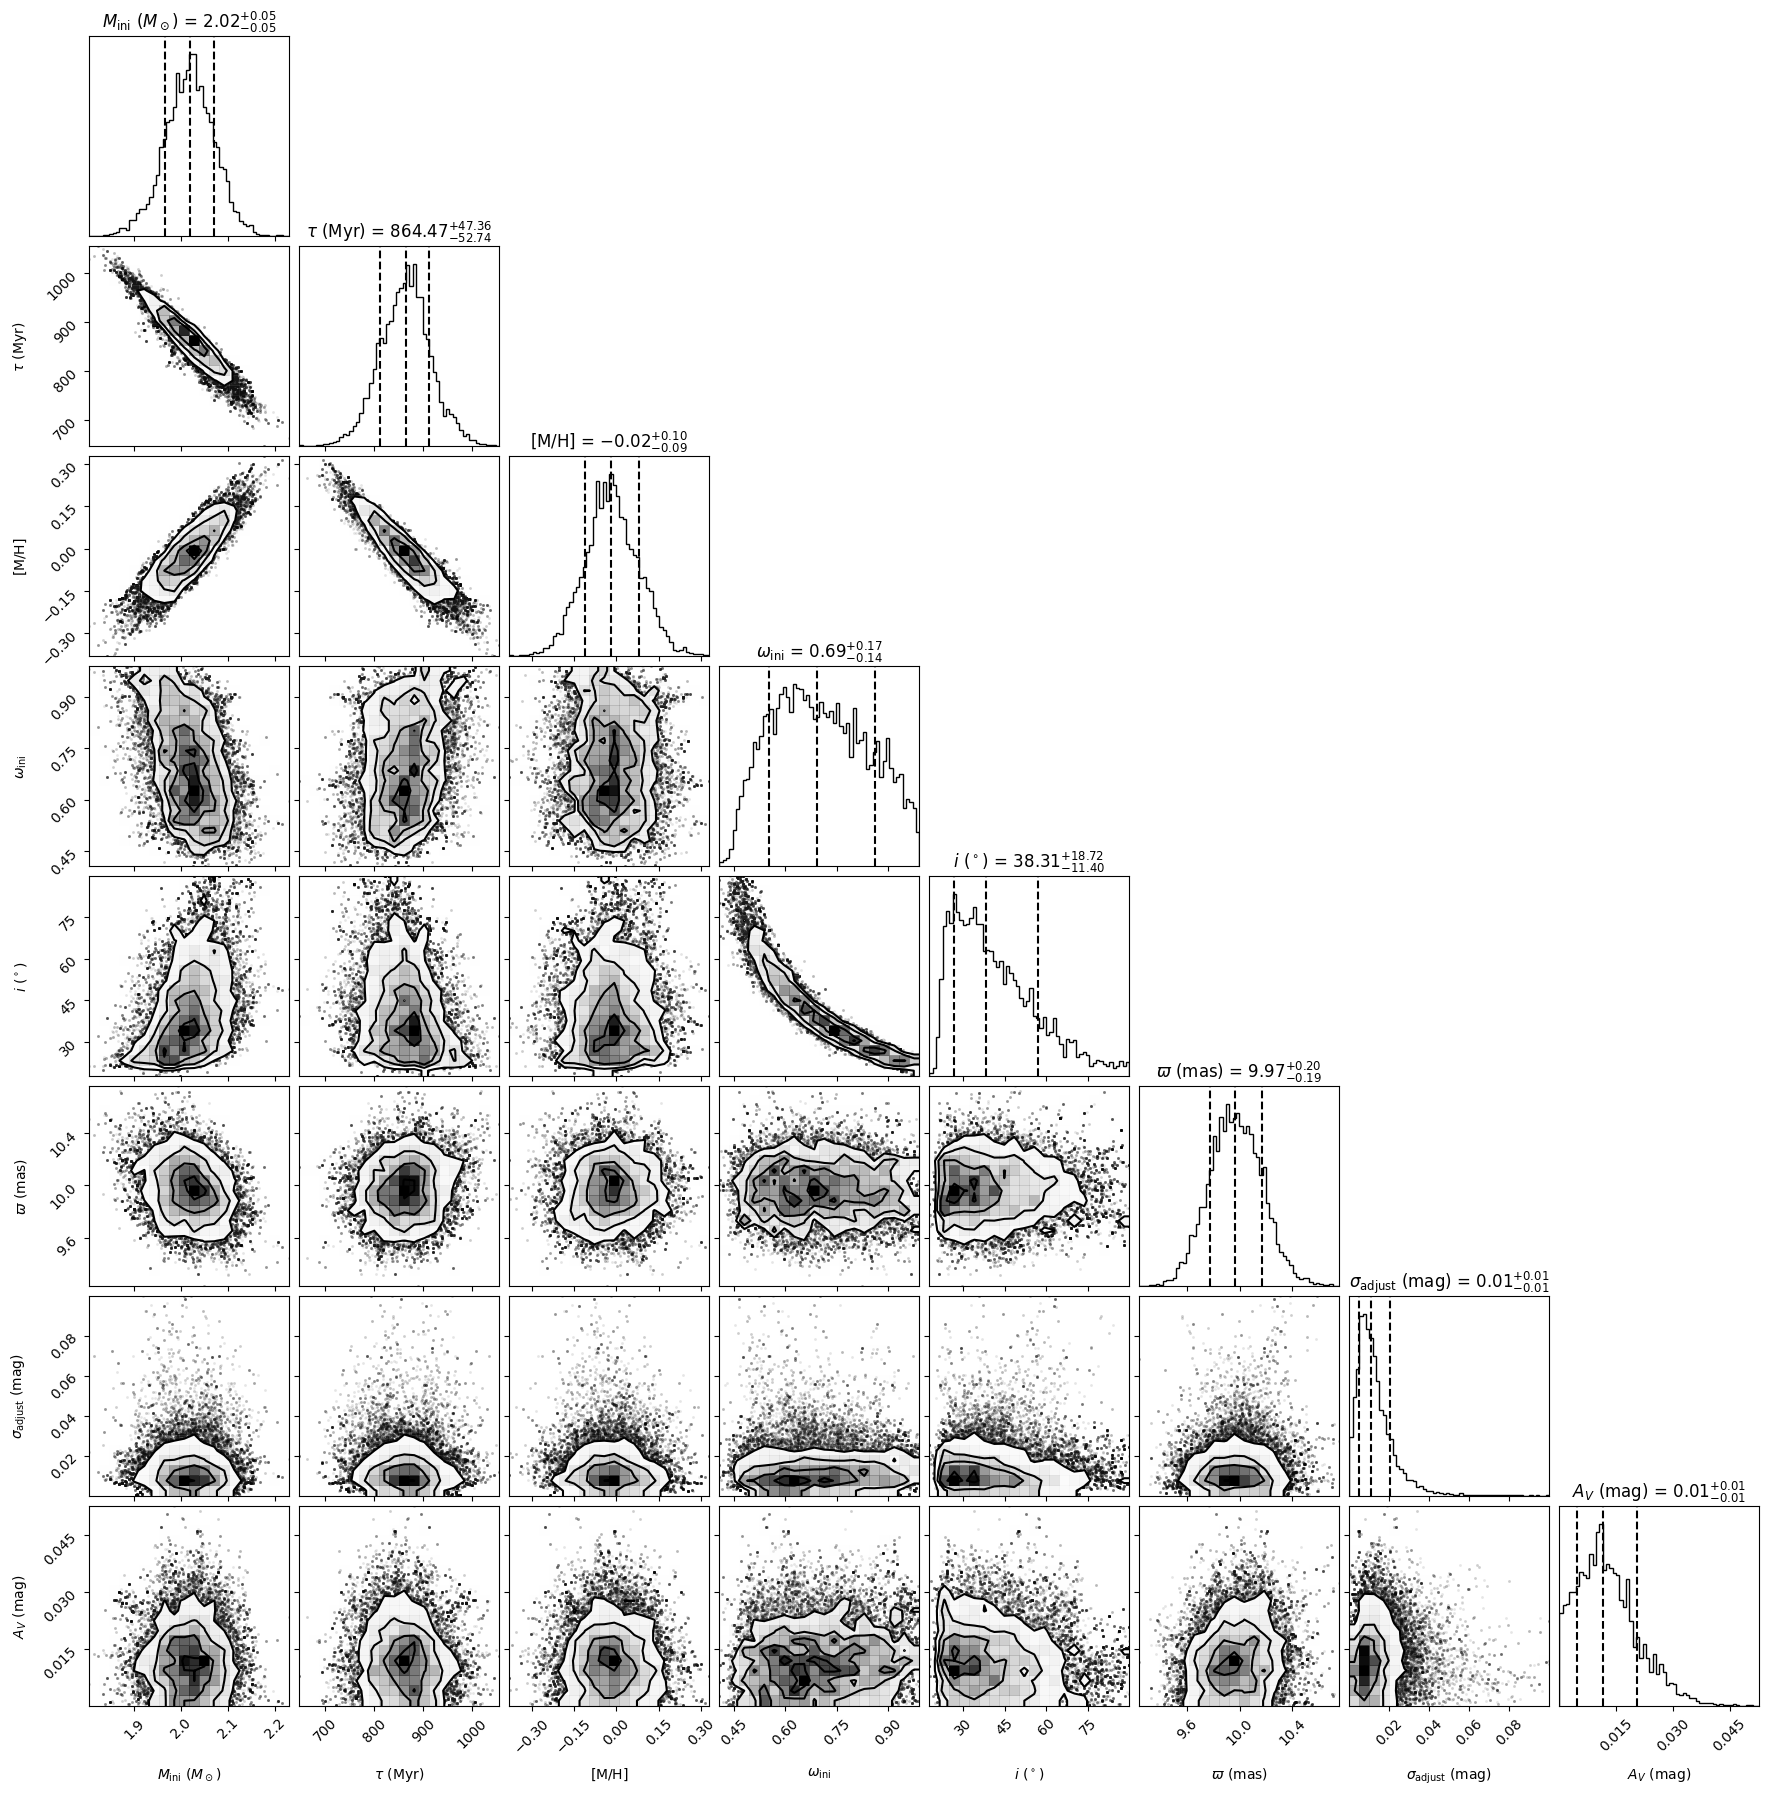

In [8]:
# quick-look tests

target.emcee_moves = [
    (emcee.moves.StretchMove(a=2.0),         0.50),
    (emcee.moves.DEMove(gamma0=0.40),        0.20),
    (emcee.moves.DESnookerMove(),            0.15),
    (emcee.moves.KDEMove(),                  0.15),
]

# target.emcee_moves = [
#     (emcee.moves.StretchMove(a=2.0),         0.95),
#     (emcee.moves.KDEMove(),                  0.05),
# ]

# target.Vrot_prior = None
# target.Vrot_prior = lambda x: 0
mcmc.target = target

sampler_test, target = mcmc.run_test_sampling(
    # n_steps_evaluate=1000,
    n_steps_test=3000,
    n_processes=8,
    save_samples=False,
)

In [9]:
# Run sampling!
# Set max time for running and processes for parallel

mcmc.target = target
sampler = mcmc.run_sampling(initial_steps = 10000, # the interval for checking convergence (e.g. 10000, 30000, 60000)
                            max_hours=10, # hours; if reaching max_hours, stop sampling anyway.
                            n_processes=8, # the number of threads used for parallel sampling.
                            )

# Play sounds to indicate completion. (For Mac only.)
for _ in range(3):
	os.system("afplay /System/Library/Sounds/Glass.aiff")

🔄 Initial sampling: 10000 steps


100%|██████████| 10000/10000 [00:58<00:00, 171.47it/s]


🚀 Standard criteria: usable N/τ ≥ 70, τ_diff < 20%

🔍 Checkpoint @ 10000 steps (elapsed 0h 0m)
  τ₀․₅=306.2, τ₀․₃=227.8, τ_diff=25.6%
  Usable N/τ after burn=10τ: 22.7 / 70
⏱ Next: 10000 steps (missing 47.3τ, planned 47.3τ; capped from 14499)


100%|██████████| 10000/10000 [00:57<00:00, 174.68it/s]



🔍 Checkpoint @ 20000 steps (elapsed 0h 1m)
  τ₀․₅=477.0, τ₀․₃=361.0, τ_diff=24.3%
  Usable N/τ after burn=10τ: 31.9 / 70
⏱ Next: 10000 steps (missing 38.1τ, planned 38.1τ; capped from 18157)


100%|██████████| 10000/10000 [00:57<00:00, 173.43it/s]



🔍 Checkpoint @ 30000 steps (elapsed 0h 2m)
  τ₀․₅=508.5, τ₀․₃=337.7, τ_diff=33.6%
  Usable N/τ after burn=10τ: 49.0 / 70
⏱ Next: 10000 steps (missing 21.0τ, planned 21.0τ; capped from 10678)


100%|██████████| 10000/10000 [00:57<00:00, 175.25it/s]



🔍 Checkpoint @ 40000 steps (elapsed 0h 3m)
  τ₀․₅=433.8, τ₀․₃=401.3, τ_diff=7.5%
  Usable N/τ after burn=10τ: 82.2 / 70
⏱ Next: 4338 steps (missing 0.0τ, planned 10.0τ)


100%|██████████| 4338/4338 [00:24<00:00, 176.11it/s]



🔍 Checkpoint @ 44338 steps (elapsed 0h 4m)
  τ₀․₅=485.3, τ₀․₃=424.0, τ_diff=12.6%
  Usable N/τ after burn=10τ: 81.4 / 70
✅ Converged: τ stable for 2 checkpoints and usable N/τ ≥ 70
Total sampling time: 00:04:16
Total MCMC steps of each walker: 44338


📏 τ₀․₅=485.3, τ₀․₃=424.0, τ_late=485.3 → burn-in=4852
Results and plots will be saved at
	/Users/ziyinggu/Programming/GitHub/BELFAST/results/almost_risky_MS_star_PARSEC_DIRECT_u_grid_sigma1_A_V_G-Tomo_A_V_prior_11
True values: [2.0, 870.0, -0.023, 0.8, 0.524, 10.0, 0, 0.01]
==> Overplot true values on the original corner plot.
Finished saving plots.


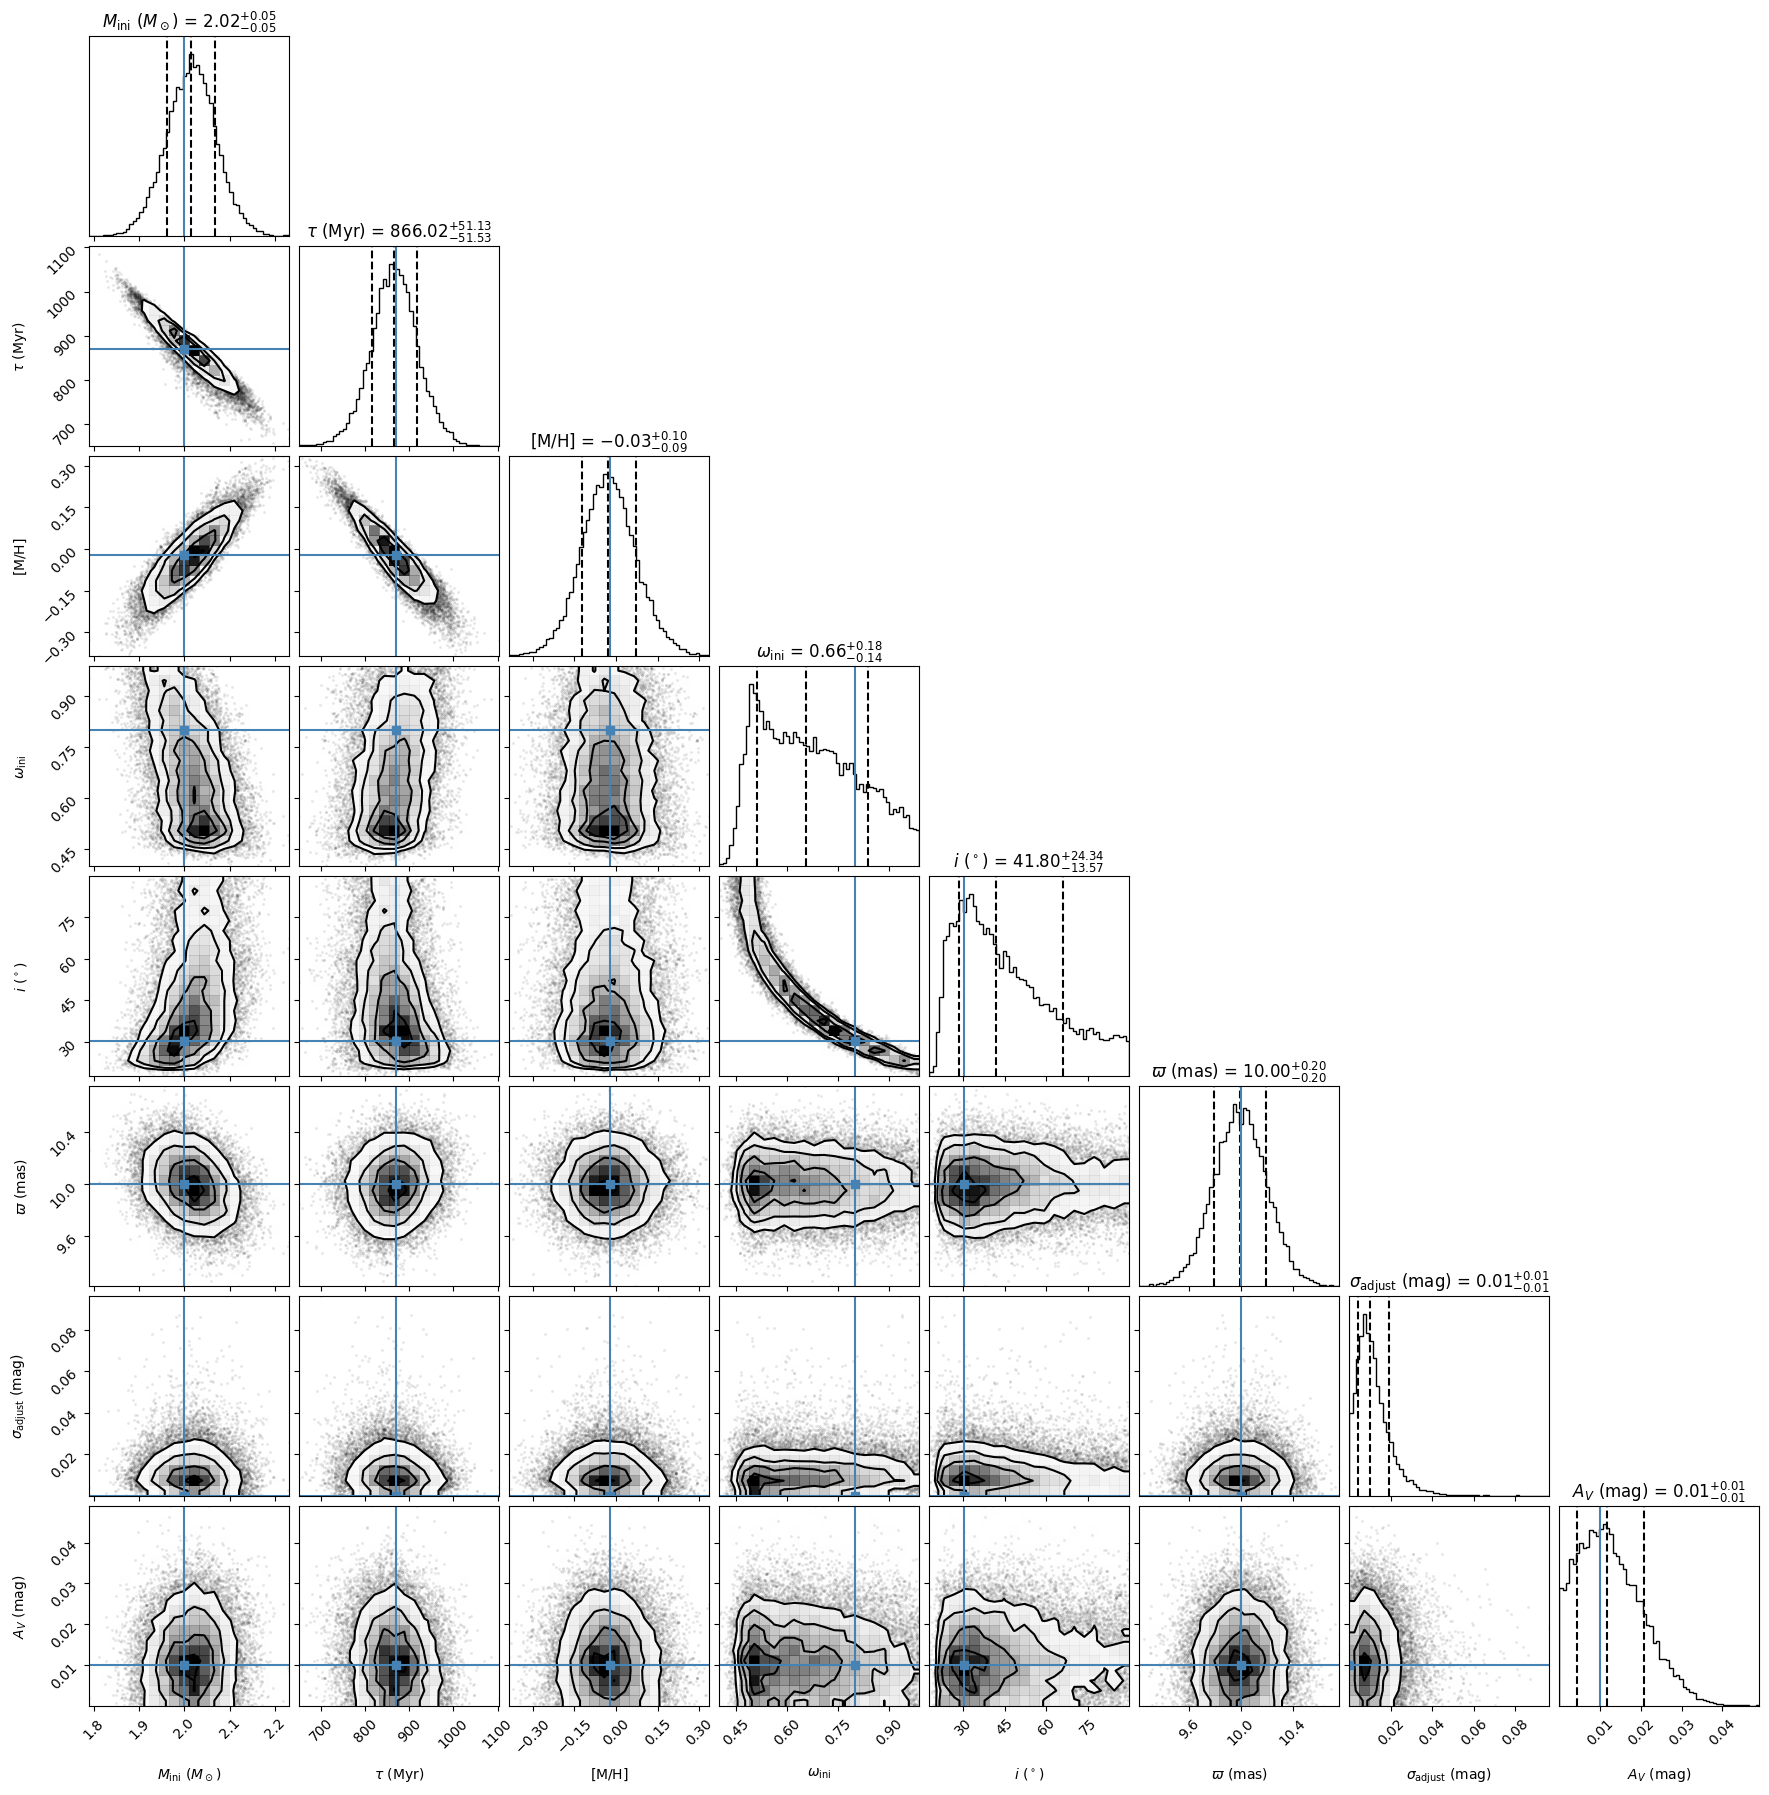

In [10]:
 # Save figures and samples, including corner plot, trace plots for all walkers, target file, and summary of results.

mcmc.target = target
target = mcmc.save_and_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior')

In [11]:
target.check_risk()


Posterior
---------------------------------------------------------------------------
Samples             (44338, 30, 8) | Blobs              (44338, 30, 21)
After discard            1,184,580 | Batch size                   5,000

Boundary grid
---------------------------------------------------------------------------
MH             -0.58314 -- 0.33637 | omega               0.300 -- 0.990
MH grid                        N=8 | omega grid                     N=6
Mass                  1.40 -- 5.00 | Mass grid                    N=361


Classifying samples: 100%|██████████| 1184580/1184580 [02:03<00:00, 9556.59samples/s]



Classification
---------------------------------------------------------------------------
Valid                    1,184,580 | Invalid                          0
Safe                       361,507 | Risky                      823,073
P(safe)                    0.30518 | P(risky)                   0.69482
